In [1]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import pandas as pd

from pathlib import Path
from datetime import datetime

from obspy import read, read_inventory
from scipy.ndimage import uniform_filter1d
from scipy.fft import rfft, irfft
from scipy.signal import correlate, correlation_lags
from scipy.ndimage import gaussian_filter1d


import gc
from obspy import Trace
from noise_corr import *

# Calcul des fonctions de corrélation

In [2]:
miniseed_files = glob.glob("C:\\SOLODATA\\bruit\\bruit\\data_mseed\\*.miniseed")
print(len(miniseed_files), "fichiers miniseed trouvés.")

109350 fichiers miniseed trouvés.


## Segmentation des signaux d'entrée

In [3]:
def segment_signal(file_path, fs=500, segment_length=60*60):
    """
    Segment a signal into smaller parts.

    Args:
    file_path (str): The path to the input file.
    fs (float): The sampling frequency.
    segment_length (int): The length of each segment in seconds.

    Returns:
    list: A list of segmented signals.
    """

    st = read(file_path) # lecture des données du fichier miniseed 
    tr = st[0] # extraction de la première trace
    data = np.asarray(tr.data, dtype=np.float32) # conversion des données en tableau numpy de type float32
    samples_per_segment = int(segment_length * fs) # nombre d'échantillons par segment
    segments = [] # liste pour stocker les segments

    for start in range(0, len(data), samples_per_segment): 
        end = start + samples_per_segment 

        if end <= len(data):
            segment = data[start:end].copy()
            segment_tr = tr.copy()
            segment_tr.data = segment
            segment_tr.detrend("demean")
            segment_tr.detrend("linear")
            segment_tr.taper(max_percentage=0.025, type="cosine")
            segment_tr.filter("bandpass", freqmin=2, freqmax=70)
            segments.append(segment_tr.data.copy())
            
    return segments

## Traitement des signaux 

In [10]:
def process_signal(data, fs=500, N=1000, normalization=True, whitening=True, plot=True):
    """
    Process a signal by normalizing and whitening it.

    Args:
        data (array-like): The input signal.
        fs (float): The sampling frequency.
        N (int): The window size for the running mean.
        normalization (bool): Whether to perform normalization.
        whitening (bool): Whether to perform whitening.
        plot (bool): Whether to plot the processed signal.

    Returns:
        array-like: The processed signal.
    """

    # data = np.asarray(data, dtype=np.float32).copy()
    # # Vérification de N
    # if not isinstance(N, (int, np.integer)) or N < 0:
    #     raise ValueError("N doit être un entier positif ou nul.")

    t = np.arange(len(data)) / fs

    # plot signal brut
    if plot:
        plt.figure(figsize=(22, 4))
        plt.plot(t/3600, data, color="black", linewidth=0.3)
        plt.title("Signal brut")
        plt.xlabel("Temps (h)")
        plt.ylabel("Amplitude (counts)")
        plt.grid()
        plt.show()

    # normalisation temporelle (RAMN)
    if normalization:
        running_mean = np.abs(data).copy()
        uniform_filter1d(running_mean, size=2*N + 1, output=running_mean)
        running_mean[running_mean == 0] = np.finfo(np.float32).eps
        data /= running_mean
        if plot:
            plt.figure(figsize=(22, 4))
            plt.plot(t/3600, data, color='navy', linewidth=0.3)
            plt.xlabel("Temps (h)")
            plt.ylabel("Amplitude normalisée")
            plt.title("Signal normalisé")
            plt.grid()
            plt.show()

        del running_mean

    # blanchiment spectral/normalisation spectrale 
    if whitening:
        fft_signal = rfft(data)
        frequency = np.fft.rfftfreq(len(data), d=1/fs)
        magnitude = np.abs(fft_signal)
        smooth_sigma = 50
        smooth_magnitude = gaussian_filter1d(magnitude, sigma=smooth_sigma)
        threshold = np.finfo(float).eps * np.max(smooth_magnitude)
        smooth_magnitude = np.maximum(smooth_magnitude, threshold)
        fft_signal /= smooth_magnitude
        whitened_magnitude = np.abs(fft_signal)

        # fig, axes = plt.subplots(1, 3, figsize=(22, 4))
        # axes[0].semilogy(frequency, magnitude, color='black', linewidth=0.3)
        # axes[0].set_xlabel("Fréquence (Hz)")
        # axes[0].set_ylabel("Amplitude (UA)")
        # axes[0].set_title("Spectre du signal normalisé")
        # axes[0].grid()
        # axes[1].semilogy(frequency, smooth_magnitude, color='navy', linewidth=0.5)
        # axes[1].set_xlabel("Fréquence (Hz)")
        # axes[1].set_ylabel("Amplitude (UA)")
        # axes[1].set_title("Spectre lissé du signal normalisé")
        # axes[1].grid()
        # axes[2].semilogy(frequency, whitened_magnitude, color='red', linewidth=0.3)
        # axes[2].set_xlabel("Fréquence (Hz)")
        # axes[2].set_ylabel("Amplitude (UA)")
        # axes[2].set_title("Spectre blanchi/normalisé")
        # axes[2].grid()
        # plt.tight_layout()
        # plt.show()

        data = irfft(fft_signal, n=len(data))
        data = np.asarray(data, dtype=np.float32)
        tr = Trace(data=data)
        tr.taper(max_percentage=0.025, type="cosine")
        data = tr.data
        if plot:
            plt.figure(figsize=(22, 4))
            plt.plot(t/3600, data, color='steelblue', linewidth=0.3)
            plt.xlabel("Temps (h)")
            plt.ylabel("Amplitude (UA)")
            plt.title("Signal blanchi")
            plt.grid()
            plt.show()

    return data

## Cross-corrélations (+ plots)

In [11]:
def stack_from_files(A, B, fs=500, max_lag=30, segment_length=60*60, N=0, normalization=True, whitening=True, plot=False):

    stack = None
    corr_matrix = []
    corr_dates = []
    n_valid = 0

    # Durée attendue du signal en nombre d'échantillons
    expected_length = int(fs * segment_length)

    # ==================================================
    # LECTURE, SEGMENTATION ET CORRÉLATION
    # ==================================================

    for i, (file_a, file_b) in enumerate(zip(A, B)):

        try:
            segments_a = segment_signal(
                file_a,
                fs=fs,
                segment_length=segment_length
            )

            segments_b = segment_signal(
                file_b,
                fs=fs,
                segment_length=segment_length
            )

            segments_a = [
                process_signal(
                    sig,
                    fs=fs,
                    N=N,
                    normalization=normalization,
                    whitening=whitening,
                    plot=plot
                )
                for sig in segments_a
            ]

            segments_b = [
                process_signal(
                    sig,
                    fs=fs,
                    N=N,
                    normalization=normalization,
                    whitening=whitening,
                    plot=plot
                )
                for sig in segments_b
            ]

            if len(segments_a) != len(segments_b):
                print(
                    f"Couple {i} ignoré : "
                    f"nombre de segments différent"
                )
                continue

            # Corrélation de chaque paire de segments
            for j, (sig_a, sig_b) in enumerate(zip(segments_a, segments_b)):

                if len(sig_a) != expected_length or len(sig_b) != expected_length:
                    continue

                corr = correlate(
                    sig_a,
                    sig_b,
                    mode="full",
                    method="fft"
                )

                corr /= len(sig_a)

                lags = correlation_lags(
                    len(sig_a),
                    len(sig_b),
                    mode="full"
                ) / fs

                mask = (lags >= -max_lag) & (lags <= max_lag)

                corr_reduced = corr[mask]
                lags_reduced = lags[mask]

                corr_matrix.append(corr_reduced.copy())

                # Stockage de la date associée à la corrélation
                # À adapter si dates_communes contient les dates des fichiers
                date_segment = pd.to_datetime(dates_communes[i]) + pd.to_timedelta(
                    j * segment_length, unit='s'
                )
                corr_dates.append(date_segment)

                # Stacking progressif
                if stack is None:
                    stack = corr_reduced.astype(np.float64)
                    lags_stack = lags_reduced.copy()

                else:
                    stack += corr_reduced

                n_valid += 1

                del corr, corr_reduced, lags, mask

            if (i + 1) % 100 == 0:
                print(
                    f"{i + 1}/{len(A)} fichiers traités "
                    f"({n_valid} corrélations stackées)"
                )

            del segments_a, segments_b
            gc.collect()

        except Exception as e:
            print(f"Erreur au couple {i} : {e}")

    # ==================================================
    # VÉRIFICATION
    # ==================================================

    if n_valid == 0:
        raise ValueError("Aucune corrélation valide")

    print(
        f"\nStacking terminé : {n_valid} corrélations utilisées"
    )

    corr_matrix = np.array(corr_matrix)

    print("Dimensions de la matrice :", corr_matrix.shape)

    # ==================================================
    # NORMALISATION INDIVIDUELLE DES CORRÉLATIONS
    # ==================================================

    max_values = np.max(
        np.abs(corr_matrix),
        axis=1,
        keepdims=True
    )

    corr_matrix_norm = np.divide(
        corr_matrix,
        max_values,
        out=np.zeros_like(corr_matrix, dtype=np.float64),
        where=max_values != 0
    )

    # ==================================================
    # STACK MOYEN
    # ==================================================

    stack /= n_valid

    max_stack = np.max(np.abs(stack))

    if max_stack == 0:
        raise ValueError("Le stack est nul : normalisation impossible")

    norm_stack = stack / max_stack

    negative_mask = lags_stack <= 0
    positive_mask = lags_stack >= 0

    negative_lags = lags_stack[negative_mask]
    negative_stack = norm_stack[negative_mask]

    positive_lags = lags_stack[positive_mask]
    positive_stack = norm_stack[positive_mask]

    negative_stack_reversed = negative_stack[::-1]

    average_stack = (
        positive_stack + negative_stack_reversed
    ) / 2

    max_average = np.max(np.abs(average_stack))

    if max_average != 0:
        average_stack /= max_average

    # ==================================================
    # FIGURE 1 : CORRELOGRAMME AVEC DATES SUR L'AXE Y
    # ==================================================

    import matplotlib.dates as mdates

    fig, ax = plt.subplots(figsize=(18, 8))

    corr_dates = pd.to_datetime(corr_dates)

    im = ax.imshow(
        corr_matrix_norm,
        aspect='auto',
        origin='lower',
        extent=[
            lags_stack[0],
            lags_stack[-1],
            mdates.date2num(corr_dates.iloc[0] if hasattr(corr_dates, 'iloc') else corr_dates[0]),
            mdates.date2num(corr_dates.iloc[-1] if hasattr(corr_dates, 'iloc') else corr_dates[-1])
        ],
        cmap='seismic',
        interpolation='nearest',
        vmin=-1,
        vmax=1
    )

    ax.set_xlabel("Lag (s)")
    ax.set_ylabel("Date et heure")

    ax.set_title(
        f"Corrélogramme normalisé des {n_valid} cross-correlations "
        f"/ Stations {station_A} ({component_A}) et "
        f"{station_B} ({component_B})\n"
        f"Durée des signaux : {segment_length/60:g} min "
        f"- du {dates_communes[0]} au {dates_communes[-1]}"
    )

    ax.yaxis_date()

    ax.yaxis.set_major_formatter(
        mdates.DateFormatter('%d/%m/%Y %H:%M')
    )

    # Un tick toutes les 24 heures
    ax.yaxis.set_major_locator(
        mdates.HourLocator(interval=24)
    )

    ax.set_xlim(-2, 2)

    cbar = plt.colorbar(im, ax=ax, orientation='vertical')
    cbar.set_label("Amplitude normalisée")
    cbar.set_ticks([-1, -0.5, 0, 0.5, 1])

    plt.tight_layout()
    plt.show()

    # ==================================================
    # FIGURE 2 : STACK CAUSAL ET ACAUSAL
    # ==================================================

    fig, axes = plt.subplots(2, 1, figsize=(22, 8), sharex=True)

    axes[0].plot(
        negative_lags,
        negative_stack,
        label="Partie acausale",
        color='lightcoral'
    )

    axes[0].plot(
        positive_lags,
        positive_stack,
        label="Partie causale",
        color='dodgerblue'
    )

    axes[0].grid()
    axes[0].legend()

    axes[0].set_title(
        f"Stack des {n_valid} cross-correlations "
        f"/ Stations {station_A} ({component_A}) et "
        f"{station_B} ({component_B})\n"
        f"Durée des signaux : {segment_length/60:g} min "
        f"- du {dates_communes[0]} au {dates_communes[-1]}"
    )

    axes[0].set_xlim(-2, 2)
    axes[0].set_ylabel("Amplitude normalisée")

    # ==================================================
    # FIGURE 3 : MOYENNE CAUSALE / ACAUSALE
    # ==================================================

    axes[1].plot(
        positive_lags,
        average_stack,
        label="Moyenne des parties causale et acausale",
        color='orchid'
    )

    max_index = np.argmax(np.abs(average_stack))
    peak_lag = positive_lags[max_index]
    max_value = average_stack[max_index]

    axes[1].scatter(
        peak_lag,
        max_value,
        color='black',
        s=50,
        zorder=5, label=f"Max : {max_value:.4f} à {peak_lag:.4f} s"
    )

    print(
        f"Maximum de la fonction de corrélation stackée : "
        f"{max_value:.4f} à un lag de {peak_lag:.4f} s"
    )

    axes[1].set_xlabel("Lags (s)")
    axes[1].set_ylabel("Amplitude normalisée")
    axes[1].set_xlim(-2, 2)
    axes[1].grid()
    axes[1].legend(loc="best")

    plt.tight_layout()
    plt.show()

    return peak_lag, positive_lags, average_stack

# Exemple

100/549 fichiers traités (100 corrélations stackées)
200/549 fichiers traités (200 corrélations stackées)
300/549 fichiers traités (300 corrélations stackées)
400/549 fichiers traités (400 corrélations stackées)
500/549 fichiers traités (500 corrélations stackées)
Couple 548 ignoré : nombre de segments différent

Stacking terminé : 548 corrélations utilisées
Dimensions de la matrice : (548, 30001)


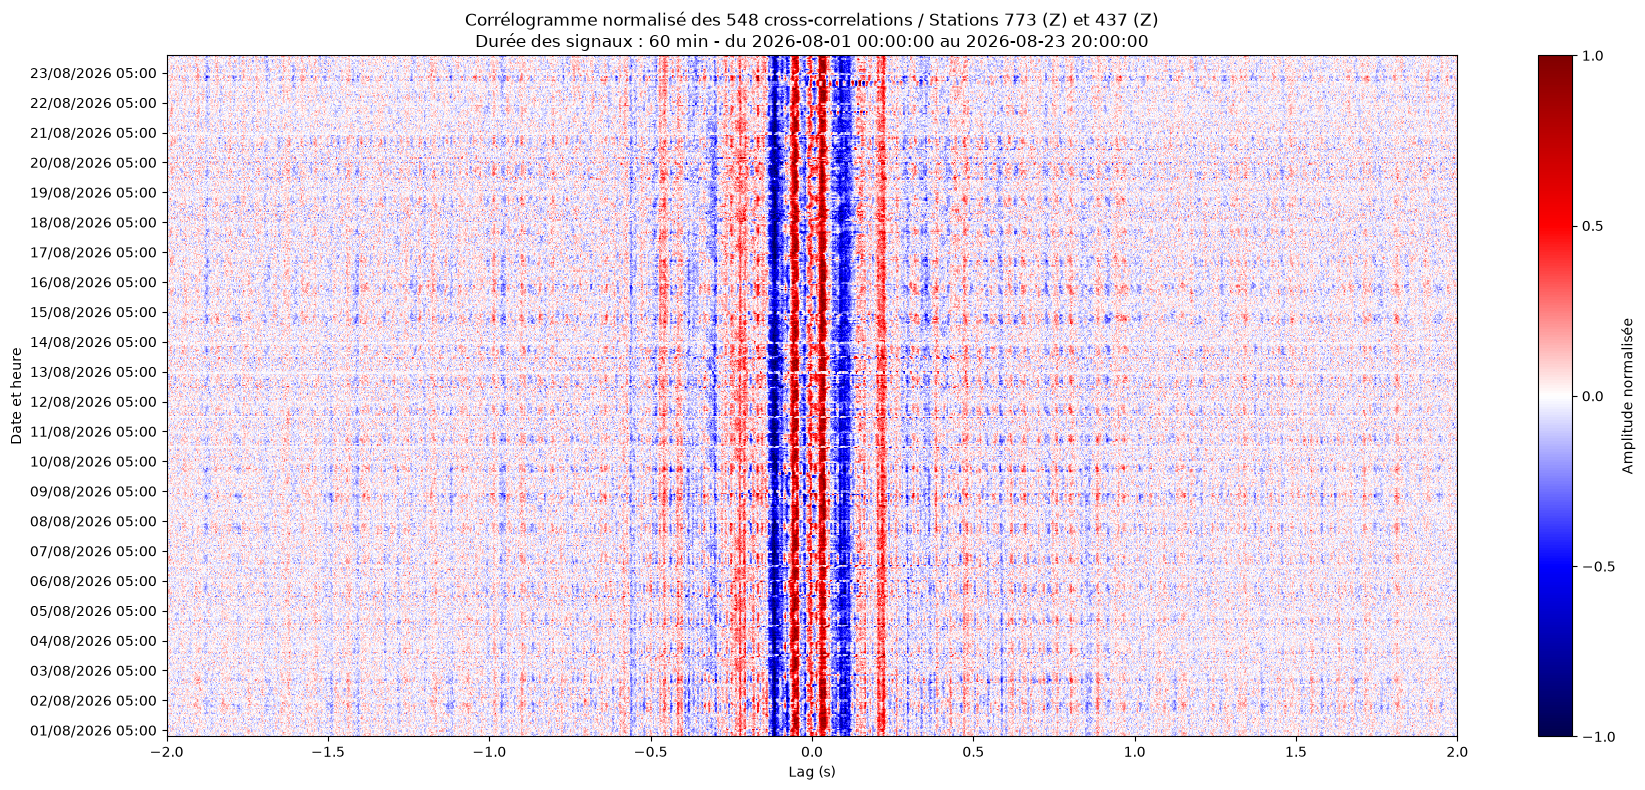

Maximum de la fonction de corrélation stackée : -1.0000 à un lag de 0.1160 s


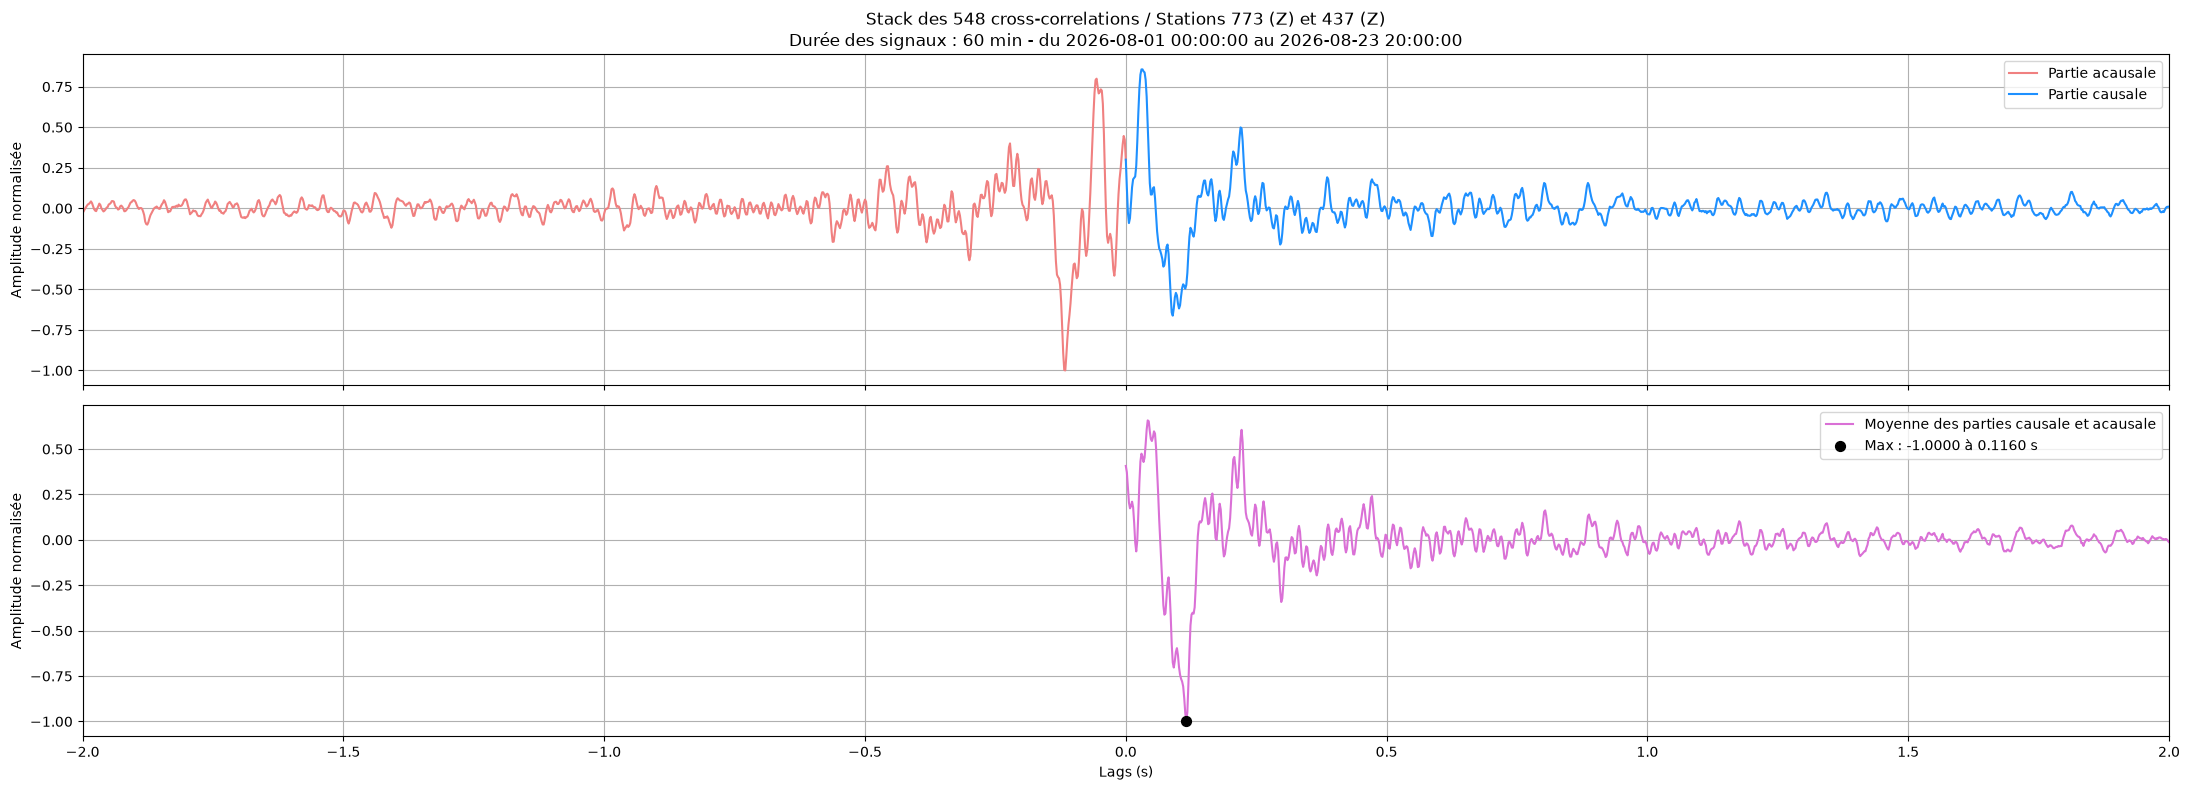

In [13]:
station_A = "773"
component_A = "Z"

station_B = "437"
component_B = "Z"

start_date = "2026-08-01"
end_date = "2026-08-30"

x = 60 # Durée des segments d'entrée en minutes
segment_length = x * 60  # Durée du segment en secondes

A, B, dates_communes = get_station_data(miniseed_files, station_A, station_B, 
                                        component_A, component_B, 
                                        start_date, end_date)

peak_lag = stack_from_files(A, B, fs=500, max_lag=30, segment_length=segment_length, N=0, normalization=True, whitening=True, plot=False)

In [ ]:
station_A = "773"
component_A = "Z"

station_B = "710"
component_B = "Z"

start_date = "2026-08-01"
end_date = "2026-08-30"

x = 60 # Durée des segments d'entrée en minutes
segment_length = x * 60  # Durée du segment en secondes

A, B, dates_communes = get_station_data(miniseed_files, station_A, station_B, 
                                        component_A, component_B, 
                                        start_date, end_date)

peak_lag = stack_from_files(A, B, fs=500, max_lag=30, segment_length=segment_length, N=0, normalization=True, whitening=True, plot=False)

100/549 fichiers traités (100 corrélations stackées)
200/549 fichiers traités (200 corrélations stackées)
300/549 fichiers traités (300 corrélations stackées)


In [ ]:
station_A = "773"
component_A = "Z"

station_B = "846"
component_B = "Z"

start_date = "2026-08-01"
end_date = "2026-08-30"

x = 60 # Durée des segments d'entrée en minutes
segment_length = x * 60  # Durée du segment en secondes

A, B, dates_communes = get_station_data(miniseed_files, station_A, station_B, 
                                        component_A, component_B, 
                                        start_date, end_date)

peak_lag = stack_from_files(A, B, fs=500, max_lag=30, segment_length=segment_length, N=0, normalization=True, whitening=True, plot=False)

In [ ]:
station_A = "773"
component_A = "Z"

station_B = "767"
component_B = "Z"

start_date = "2026-08-01"
end_date = "2026-08-30"

x = 60 # Durée des segments d'entrée en minutes
segment_length = x * 60  # Durée du segment en secondes

A, B, dates_communes = get_station_data(miniseed_files, station_A, station_B, 
                                        component_A, component_B, 
                                        start_date, end_date)

peak_lag = stack_from_files(A, B, fs=500, max_lag=30, segment_length=segment_length, N=0, normalization=True, whitening=True, plot=False)